# FakeLens — Image Forgery Localization

**Author:** Nikita Nizov

FakeLens is a computer vision project for pixel-level localization of manipulated image regions, including copy-move and image splicing forgeries.

The model combines a pretrained DINOv3 ViT-L backbone, LoRA-based fine-tuning, and a lightweight convolutional segmentation decoder.

### Project overview

- **Backbone:** DINOv3 ViT-L (~303M parameters)
- **Fine-tuning:** LoRA (rank=32, alpha=64)
- **Input resolution:** 512 × 512
- **Training dataset:** CASIA v2
- **Training environment:** Google Colab, NVIDIA T4
- **Evaluation datasets:** CASIA v2, Columbia, COVERAGE

### Interactive demo

https://huggingface.co/spaces/T1-Reks/fakelens

**Scope:** FakeLens localizes image manipulation regions. It is not designed to detect fully AI-generated images.

# Environment setup

## GPU and dependencies

In [ ]:
# Check the available GPU and its memory
!nvidia-smi

Wed Oct 14 18:03:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             28W /   70W |    6337MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Install required libraries
!pip install -q -U transformers accelerate peft huggingface_hub

In [ ]:
# Remove incompatible torchao package that is not required for this project

!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## Imports and configuration

In [ ]:
# Import required libraries
import os
import random
import numpy as np
import torch

from transformers import AutoImageProcessor, AutoModel
from huggingface_hub import login

In [ ]:
# Set random seed, model configuration, and device
SEED = 30
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_NAME = "facebook/dinov3-vitl16-pretrain-lvd1689m"
IMAGE_SIZE = 512

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

Device: cuda


# DINOv3 backbone

## Hugging Face authentication

In [ ]:
# Load the Hugging Face access token and authenticate
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")
login(token=HF_TOKEN)

print("Hugging Face authentication successful")

Hugging Face authentication successful


## Model loading

In [ ]:
# Load the DINOv3 image processor and pretrained ViT-L backbone in FP32

processor = AutoImageProcessor.from_pretrained(MODEL_NAME, token=HF_TOKEN)
backbone = AutoModel.from_pretrained(MODEL_NAME, token=HF_TOKEN)
backbone = backbone.to(DEVICE)

print(f"Model parameters: {sum(p.numel() for p in backbone.parameters()) / 1e6:.1f}M")

Model parameters: 303.1M


# Backbone smoke test

## Input preparation

In [ ]:
# Create a dummy 512x512 image and prepare it for DINOv3

from PIL import Image

image = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (128, 128, 128))
inputs = processor(images=image, return_tensors="pt", do_resize=False, do_center_crop=False)
inputs["pixel_values"] = inputs["pixel_values"].to(DEVICE)

print("Input shape:", inputs["pixel_values"].shape)
print("Input dtype:", inputs["pixel_values"].dtype)

Input shape: torch.Size([1, 3, 512, 512])
Input dtype: torch.float32


## Forward pass and feature extraction

In [ ]:
# Run a forward pass and measure peak GPU memory usage
backbone.eval()

torch.cuda.reset_peak_memory_stats()

with torch.inference_mode():
    outputs = backbone(**inputs)

print("Last hidden state:", outputs.last_hidden_state.shape)
print("Peak VRAM:", round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GB")

Last hidden state: torch.Size([1, 1029, 1024])
Peak VRAM: 1.19 GB


In [ ]:
# Extract spatial patch tokens for future segmentation
patch_tokens = outputs.last_hidden_state[:, 5:, :]

print("Patch tokens:", patch_tokens.shape)

Patch tokens: torch.Size([1, 1024, 1024])


# LoRA adaptation

## LoRA configuration

In [ ]:
# Add LoRA adapters to the attention QKV projections

from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(r=32, lora_alpha=64, target_modules=["q_proj", "k_proj", "v_proj"], lora_dropout=0.0, bias="none")
backbone = get_peft_model(backbone, lora_config)

backbone.print_trainable_parameters()

trainable params: 4,718,592 || all params: 307,848,192 || trainable%: 1.5328


## Backward smoke test

In [ ]:
# Check whether DINOv3 produces finite features

backbone.eval()

with torch.no_grad():
    outputs = backbone(**inputs)

features = outputs.last_hidden_state[:, 5:, :].float()

print("NaN:", torch.isnan(features).any().item())
print("Inf:", torch.isinf(features).any().item())
print("Finite ratio:", torch.isfinite(features).float().mean().item())

NaN: False
Inf: False
Finite ratio: 1.0


In [ ]:
# Test forward and backward passes with LoRA at 512x512

backbone.train()
backbone.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

outputs = backbone(**inputs)
loss = outputs.last_hidden_state[:, 5:, :].float().square().mean()
loss.backward()

print("Loss:", loss.item())
print("Peak VRAM:", round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GB")

Loss: 0.08672025054693222
Peak VRAM: 2.26 GB


# Segmentation model

## Decoder

In [ ]:
# Define a lightweight decoder that converts DINOv3 features into a segmentation mask

import torch.nn as nn
import torch.nn.functional as F

class SegmentationDecoder(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, 256, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(16, 256)

        self.conv2 = nn.Conv2d(256, 64, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(8, 64)

        self.conv3 = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x, output_size):
        x = F.gelu(self.norm1(self.conv1(x)))
        x = F.gelu(self.norm2(self.conv2(x)))
        x = self.conv3(x)
        x = F.interpolate(x, size=output_size, mode="bilinear", align_corners=False)

        return x

## Full model

In [ ]:
# Combine the DINOv3-LoRA backbone and segmentation decoder into one model

class ForgeryLensModel(nn.Module):
    def __init__(self, backbone):
        super().__init__()

        self.backbone = backbone
        self.hidden_size = backbone.config.hidden_size
        self.patch_size = backbone.config.patch_size
        self.decoder = SegmentationDecoder(self.hidden_size)

    def forward(self, pixel_values):
        outputs = self.backbone(pixel_values=pixel_values)

        height, width = pixel_values.shape[-2:]
        grid_height = height // self.patch_size
        grid_width = width // self.patch_size
        num_patches = grid_height * grid_width

        patch_tokens = outputs.last_hidden_state[:, -num_patches:, :]
        features = patch_tokens.transpose(1, 2).reshape(pixel_values.shape[0], self.hidden_size, grid_height, grid_width)

        logits = self.decoder(features, (height, width))

        return logits

In [ ]:
# Create the complete ForgeryLens model and display its parameter counts

model = ForgeryLensModel(backbone).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params / 1e6:.1f}M")
print(f"Trainable parameters: {trainable_params / 1e6:.1f}M")
print(f"Trainable ratio: {100 * trainable_params / total_params:.2f}%")

Total parameters: 310.4M
Trainable parameters: 7.2M
Trainable ratio: 2.33%


## Segmentation smoke test

In [ ]:
# Check that the complete model produces a full-resolution segmentation mask

model.eval()

with torch.no_grad():
    logits = model(inputs["pixel_values"])

print("Output shape:", logits.shape)
print("NaN:", torch.isnan(logits).any().item())
print("Inf:", torch.isinf(logits).any().item())

Output shape: torch.Size([1, 1, 512, 512])
NaN: False
Inf: False


In [ ]:
# Verify backward propagation through the decoder and LoRA adapters

model.train()
model.zero_grad(set_to_none=True)

target = torch.zeros((1, 1, IMAGE_SIZE, IMAGE_SIZE), device=DEVICE)
target[:, :, 128:384, 128:384] = 1.0

criterion = nn.BCEWithLogitsLoss()

torch.cuda.reset_peak_memory_stats()

logits = model(inputs["pixel_values"])
loss = criterion(logits, target)
loss.backward()

gradients = [p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
finite_gradients = all(torch.isfinite(grad).all().item() for grad in gradients)

print("Loss:", loss.item())
print("Finite gradients:", finite_gradients)
print("Peak VRAM:", round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GB")

Loss: 0.6487443447113037
Finite gradients: True
Peak VRAM: 2.31 GB


# Dataset preparation

## CASIA v2 download

In [ ]:
# Download the corrected CASIA v2 dataset with ground-truth masks

!pip install -q gdown
!gdown 1JN93ts7VxJ4bbJL9TlE9uxM3ZeYuCN9M -O /content/casia2.zip

Downloading...
From (original): https://drive.google.com/uc?id=1JN93ts7VxJ4bbJL9TlE9uxM3ZeYuCN9M
From (redirected): https://drive.google.com/uc?id=1JN93ts7VxJ4bbJL9TlE9uxM3ZeYuCN9M&confirm=t&uuid=5fb5caec-0d62-4958-a70d-8efda2ee6249
To: /content/casia2.zip
100% 2.68G/2.68G [00:32<00:00, 81.5MB/s]


In [ ]:
# Extract CASIA v2 and skip files that already exist

!mkdir -p /content/casia2
!unzip -nq /content/casia2.zip -d /content/casia2

In [ ]:
# Find the authentic, tampered, and ground-truth directories

from pathlib import Path

CASIA_ROOT = Path("/content/casia2")

for path in CASIA_ROOT.rglob("*"):
    if path.is_dir() and path.name in {"Au", "Tp", "Gt"}:
        print(path)

/content/casia2/casia/Gt
/content/casia2/casia/Au
/content/casia2/casia/Tp


In [ ]:
# Count images in each CASIA v2 directory

for folder_name in ["Au", "Tp", "Gt"]:
    folders = [path for path in CASIA_ROOT.rglob(folder_name) if path.is_dir()]

    for folder in folders:
        files = [path for path in folder.iterdir() if path.is_file()]
        print(folder_name, len(files), folder)

Au 7492 /content/casia2/casia/Au
Tp 5123 /content/casia2/casia/Tp
Gt 5123 /content/casia2/casia/Gt


## File pairing

In [ ]:
# Define CASIA v2 directory paths

CASIA_ROOT = Path("/content/casia2/casia")

AU_DIR = CASIA_ROOT / "Au"
TP_DIR = CASIA_ROOT / "Tp"
GT_DIR = CASIA_ROOT / "Gt"

In [ ]:
# Inspect sample filenames from authentic, tampered, and ground-truth directories

for folder_name, folder in [("Au", AU_DIR), ("Tp", TP_DIR), ("Gt", GT_DIR)]:
    print(f"\n{folder_name}:")
    for path in sorted(folder.iterdir())[:10]:
        print(path.name)


Au:
Au_ani_00001.jpg
Au_ani_00002.jpg
Au_ani_00003.jpg
Au_ani_00004.jpg
Au_ani_00005.jpg
Au_ani_00006.jpg
Au_ani_00007.jpg
Au_ani_00008.jpg
Au_ani_00009.jpg
Au_ani_00010.jpg

Tp:
Tp_D_CND_M_N_ani00018_sec00096_00138.tif
Tp_D_CND_M_N_art00076_art00077_10289.tif
Tp_D_CND_M_N_art00077_art00076_10290.tif
Tp_D_CND_S_N_ani00073_ani00068_00193.tif
Tp_D_CND_S_N_ind00078_ind00077_00476.tif
Tp_D_CND_S_N_txt00028_txt00006_10848.jpg
Tp_D_CNN_M_B_nat00056_nat00099_11105.jpg
Tp_D_CNN_M_B_nat10139_nat00059_11949.jpg
Tp_D_CNN_M_B_nat10139_nat00097_11948.jpg
Tp_D_CNN_M_N_ani00023_ani00024_10205.tif

Gt:
Tp_D_CND_M_N_ani00018_sec00096_00138_gt.png
Tp_D_CND_M_N_art00076_art00077_10289_gt.png
Tp_D_CND_M_N_art00077_art00076_10290_gt.png
Tp_D_CND_S_N_ani00073_ani00068_00193_gt.png
Tp_D_CND_S_N_ind00078_ind00077_00476_gt.png
Tp_D_CND_S_N_txt00028_txt00006_10848_gt.png
Tp_D_CNN_M_B_nat00056_nat00099_11105_gt.png
Tp_D_CNN_M_B_nat10139_nat00059_11949_gt.png
Tp_D_CNN_M_B_nat10139_nat00097_11948_gt.png
Tp_D_CNN_

In [ ]:
# Count file extensions in each dataset directory

from collections import Counter

for folder_name, folder in [("Au", AU_DIR), ("Tp", TP_DIR), ("Gt", GT_DIR)]:
    extensions = Counter(path.suffix.lower() for path in folder.iterdir() if path.is_file())
    print(folder_name, extensions)

Au Counter({'.jpg': 7437, '.bmp': 54, '.db': 1})
Tp Counter({'.tif': 3059, '.jpg': 2064})
Gt Counter({'.png': 5123})


## Dataset index

In [ ]:
# Build a dataset index and pair tampered images with their ground-truth masks

VALID_EXTENSIONS = {".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".png"}

authentic_paths = sorted(path for path in AU_DIR.iterdir() if path.suffix.lower() in VALID_EXTENSIONS)
tampered_paths = sorted(path for path in TP_DIR.iterdir() if path.suffix.lower() in VALID_EXTENSIONS)

records = [{"image_path": path, "mask_path": None, "label": 0} for path in authentic_paths]

for image_path in tampered_paths:
    mask_path = GT_DIR / f"{image_path.stem}_gt.png"
    records.append({"image_path": image_path, "mask_path": mask_path, "label": 1})

missing_masks = [record["image_path"] for record in records if record["label"] == 1 and not record["mask_path"].exists()]

print("Authentic:", len(authentic_paths))
print("Tampered:", len(tampered_paths))
print("Total:", len(records))
print("Missing masks:", len(missing_masks))

Authentic: 7491
Tampered: 5123
Total: 12614
Missing masks: 0


## Train-validation split

The CASIA v2 dataset was split into training (80%) and validation (20%) subsets using a fixed random seed.

Stratified sampling was applied to preserve the proportion of authentic and tampered images in both subsets.

- **Training:** 10,091 images (4,098 tampered)
- **Validation:** 2,523 images (1,025 tampered)

**Limitation:** The split was performed at the image level without grouping related images by their original source. Therefore, potential overlap between related images across the training and validation subsets was not explicitly ruled out.

In [ ]:
# Split the dataset into stratified training and validation sets

from sklearn.model_selection import train_test_split

train_records, val_records = train_test_split(records, test_size=0.2, random_state=SEED, stratify=[record["label"] for record in records])

print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Train tampered:", sum(record["label"] for record in train_records))
print("Validation tampered:", sum(record["label"] for record in val_records))

Train: 10091
Validation: 2523
Train tampered: 4098
Validation tampered: 1025


## PyTorch dataset

In [ ]:
# Define a PyTorch dataset that prepares images and pixel-level manipulation masks

from torch.utils.data import Dataset

class CASIAForgeryDataset(Dataset):
    def __init__(self, records, processor, image_size=512):
        self.records = records
        self.processor = processor
        self.image_size = image_size

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        image = Image.open(record["image_path"]).convert("RGB")
        image = image.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)

        if record["mask_path"] is None:
            mask = np.zeros((self.image_size, self.image_size), dtype=np.float32)
        else:
            mask = Image.open(record["mask_path"]).convert("L")
            mask = mask.resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
            mask = (np.asarray(mask) > 127).astype(np.float32)

        pixel_values = self.processor(images=image, return_tensors="pt", do_resize=False, do_center_crop=False)["pixel_values"].squeeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return {"pixel_values": pixel_values, "mask": mask, "label": record["label"]}

In [ ]:
# Create the datasets and inspect one tampered training sample

train_dataset = CASIAForgeryDataset(train_records, processor, IMAGE_SIZE)
val_dataset = CASIAForgeryDataset(val_records, processor, IMAGE_SIZE)

sample_index = next(i for i, record in enumerate(train_records) if record["label"] == 1)
sample = train_dataset[sample_index]

print("Image:", sample["pixel_values"].shape, sample["pixel_values"].dtype)
print("Mask:", sample["mask"].shape, sample["mask"].dtype)
print("Label:", sample["label"])
print("Manipulated pixels:", round(sample["mask"].mean().item() * 100, 2), "%")

Image: torch.Size([3, 512, 512]) torch.float32
Mask: torch.Size([1, 512, 512]) torch.float32
Label: 1
Manipulated pixels: 0.58 %


# Data validation

## Visual inspection

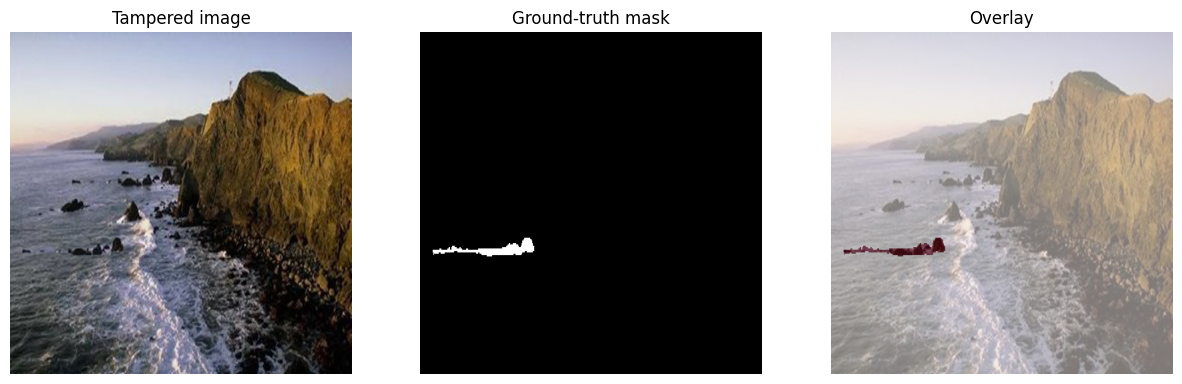

In [ ]:
# Visualize a tampered image, its ground-truth mask, and the overlay

import matplotlib.pyplot as plt

record = train_records[sample_index]

image = Image.open(record["image_path"]).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
mask = Image.open(record["mask_path"]).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST)
mask = np.asarray(mask) > 127

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Tampered image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground-truth mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, alpha=0.5, cmap="Reds")
plt.title("Overlay")
plt.axis("off")

plt.show()

# Training setup

## Data loaders

In [ ]:
# Create training and validation data loaders

from torch.utils.data import DataLoader

BATCH_SIZE = 4

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

batch = next(iter(train_loader))

print("Images:", batch["pixel_values"].shape)
print("Masks:", batch["mask"].shape)
print("Labels:", batch["label"].shape)

Images: torch.Size([4, 3, 512, 512])
Masks: torch.Size([4, 1, 512, 512])
Labels: torch.Size([4])


## Segmentation loss

In [ ]:
# Define combined BCE and Dice loss for imbalanced segmentation masks

def dice_loss(logits, targets, eps=1e-6):
    probabilities = torch.sigmoid(logits)

    intersection = (probabilities * targets).sum(dim=(1, 2, 3))
    denominator = probabilities.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (denominator + eps)

    return 1 - dice.mean()

def segmentation_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    dice = dice_loss(logits, targets)

    return bce + dice

In [ ]:
# Test the complete model and segmentation loss on a real training batch

model.train()
model.zero_grad(set_to_none=True)

pixel_values = batch["pixel_values"].to(DEVICE)
masks = batch["mask"].to(DEVICE)

torch.cuda.reset_peak_memory_stats()

logits = model(pixel_values)
loss = segmentation_loss(logits, masks)
loss.backward()

print("Output:", logits.shape)
print("Loss:", loss.item())
print("Finite loss:", torch.isfinite(loss).item())
print("Peak VRAM:", round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GB")

Output: torch.Size([4, 1, 512, 512])
Loss: 1.554336667060852
Finite loss: True
Peak VRAM: 5.6 GB


# Training

## Optimizer and mixed precision

In [ ]:
# Configure separate learning rates for LoRA adapters and the segmentation decoder

LORA_LR = 1e-4
DECODER_LR = 1e-3
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW([
    {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": LORA_LR},
    {"params": model.decoder.parameters(), "lr": DECODER_LR}
], weight_decay=WEIGHT_DECAY)

scaler = torch.amp.GradScaler("cuda")

In [ ]:
# Test mixed-precision forward and backward passes without updating model weights

model.train()
model.zero_grad(set_to_none=True)

pixel_values = batch["pixel_values"].to(DEVICE)
masks = batch["mask"].to(DEVICE)

torch.cuda.reset_peak_memory_stats()

with torch.autocast(device_type="cuda", dtype=torch.float16):
    logits = model(pixel_values)
    loss = segmentation_loss(logits, masks)

scaler.scale(loss).backward()
scaler.unscale_(optimizer)

gradients = [p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
finite_gradients = all(torch.isfinite(grad).all().item() for grad in gradients)

print("Loss:", loss.item())
print("Finite loss:", torch.isfinite(loss).item())
print("Finite gradients:", finite_gradients)
print("Peak VRAM:", round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GB")

Loss: 1.5546821355819702
Finite loss: True
Finite gradients: True
Peak VRAM: 4.72 GB


## Metrics

In [ ]:
# Compute pixel-level Dice/F1 and IoU from accumulated predictions

def segmentation_metrics(logits, targets, threshold=0.5):
    predictions = torch.sigmoid(logits) >= threshold
    targets = targets.bool()

    tp = (predictions & targets).sum().item()
    fp = (predictions & ~targets).sum().item()
    fn = (~predictions & targets).sum().item()

    return tp, fp, fn


def calculate_metrics(tp, fp, fn, eps=1e-8):
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)

    return dice, iou

## Training and validation loops

In [ ]:
# Train the model for one epoch using mixed precision

from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, scaler):
    model.train()

    total_loss = 0.0

    for batch in tqdm(loader, desc="Training"):
        pixel_values = batch["pixel_values"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(pixel_values)
            loss = segmentation_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * pixel_values.size(0)

    return total_loss / len(loader.dataset)

In [ ]:
# Evaluate validation loss, pixel-level Dice/F1, and IoU

@torch.no_grad()
def validate(model, loader):
    model.eval()

    total_loss = 0.0
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for batch in tqdm(loader, desc="Validation"):
        pixel_values = batch["pixel_values"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(pixel_values)
            loss = segmentation_loss(logits, masks)

        tp, fp, fn = segmentation_metrics(logits, masks)

        total_loss += loss.item() * pixel_values.size(0)
        total_tp += tp
        total_fp += fp
        total_fn += fn

    dice, iou = calculate_metrics(total_tp, total_fp, total_fn)

    return total_loss / len(loader.dataset), dice, iou

## First training epoch

In [ ]:
# Reset the gradient scaler before actual training

scaler = torch.amp.GradScaler("cuda")

In [ ]:
# Train and validate the first epoch

train_loss = train_one_epoch(model, train_loader, optimizer, scaler)
val_loss, val_dice, val_iou = validate(model, val_loader)

print(f"Train loss: {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation Dice/F1: {val_dice:.4f}")
print(f"Validation IoU: {val_iou:.4f}")

Train loss: 0.8355
Validation loss: 0.7578
Validation Dice/F1: 0.8122
Validation IoU: 0.6838


## Full training

In [ ]:
# Train for four more epochs and save the best model by validation Dice/F1

NUM_EPOCHS = 4
best_dice = val_dice

for epoch in range(2, NUM_EPOCHS + 2):
    print(f"\nEpoch {epoch}/{NUM_EPOCHS + 1}")

    train_loss = train_one_epoch(model, train_loader, optimizer, scaler)
    val_loss, val_dice, val_iou = validate(model, val_loader)

    print(f"Train loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation Dice/F1: {val_dice:.4f}")
    print(f"Validation IoU: {val_iou:.4f}")

    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), "/content/forgerylens_best.pt")
        print("Best model saved")


Epoch 2/5


Train loss: 0.7223
Validation loss: 0.7218
Validation Dice/F1: 0.8550
Validation IoU: 0.7468
Best model saved

Epoch 3/5


Train loss: 0.6945
Validation loss: 0.7144
Validation Dice/F1: 0.8637
Validation IoU: 0.7601
Best model saved

Epoch 4/5


Train loss: 0.6774
Validation loss: 0.7249
Validation Dice/F1: 0.8509
Validation IoU: 0.7405

Epoch 5/5


Train loss: 0.6702
Validation loss: 0.7109
Validation Dice/F1: 0.8659
Validation IoU: 0.7634
Best model saved


## Model Export

In [ ]:
# Export the best LoRA adapters and segmentation decoder without the pretrained backbone

from peft import get_peft_model_state_dict

model.load_state_dict(torch.load("/content/forgerylens_best.pt", map_location=DEVICE, weights_only=True))

torch.save({
    "lora": get_peft_model_state_dict(model.backbone),
    "decoder": model.decoder.state_dict(),
    "best_dice": best_dice,
    "model_name": MODEL_NAME
}, "/content/forgerylens_compact_best.pt")

import os

print(f"Model size: {os.path.getsize('/content/forgerylens_compact_best.pt') / 1024**2:.1f} MB")

Model size: 27.6 MB


In [ ]:
# Download the best compact model

from google.colab import files

files.download("/content/forgerylens_compact_best.pt")

# Evaluation

## Best model loading

In [ ]:
# Upload the trained ForgeryLens checkpoint

from google.colab import files

files.upload()

In [ ]:
# Restore trained LoRA adapters and the segmentation decoder

from peft import set_peft_model_state_dict

checkpoint = torch.load("/content/forgerylens_compact_best.pt", map_location="cpu", weights_only=True)

assert checkpoint["model_name"] == MODEL_NAME

set_peft_model_state_dict(model.backbone, checkpoint["lora"])
model.decoder.load_state_dict(checkpoint["decoder"])

model = model.to(DEVICE)
model.eval()

BEST_THRESHOLD = 0.7

print("ForgeryLens restored successfully")
print(f"Validation Dice/F1: {checkpoint['best_dice']:.4f}")

ForgeryLens restored successfully
Validation Dice/F1: 0.8659


## Detailed validation metrics

In [ ]:
# Evaluate pixel-level segmentation quality separately for authentic and tampered images

@torch.inference_mode()
def evaluate_detailed(model, loader, threshold=0.5):
    model.eval()

    total_tp, total_fp, total_fn = 0, 0, 0
    tampered_dice = []
    authentic_false_area = []

    for batch in tqdm(loader, desc="Detailed evaluation"):
        images = batch["pixel_values"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        predictions = torch.sigmoid(logits.float()) >= threshold
        targets = masks.bool()

        tp = (predictions & targets).sum(dim=(1, 2, 3)).cpu().numpy()
        fp = (predictions & ~targets).sum(dim=(1, 2, 3)).cpu().numpy()
        fn = (~predictions & targets).sum(dim=(1, 2, 3)).cpu().numpy()

        labels = batch["label"].numpy()
        predicted_area = predictions.float().mean(dim=(1, 2, 3)).cpu().numpy()

        total_tp += tp.sum()
        total_fp += fp.sum()
        total_fn += fn.sum()

        dice = 2 * tp / (2 * tp + fp + fn + 1e-8)
        tampered_dice.extend(dice[labels == 1].tolist())
        authentic_false_area.extend(predicted_area[labels == 0].tolist())

    micro_dice, micro_iou = calculate_metrics(total_tp, total_fp, total_fn)

    print(f"Micro Dice/F1: {micro_dice:.4f}")
    print(f"Micro IoU: {micro_iou:.4f}")
    print(f"Tampered-only mean Dice/F1: {np.mean(tampered_dice):.4f}")
    print(f"Authentic false-positive area: {np.mean(authentic_false_area) * 100:.2f}%")

In [ ]:
# Run detailed validation on the best model

evaluate_detailed(model, val_loader)

Micro Dice/F1: 0.8659
Micro IoU: 0.7634
Tampered-only mean Dice/F1: 0.8244
Authentic false-positive area: 0.17%


## Prediction visualization

In [ ]:
# Select reproducible authentic and tampered validation examples

rng = np.random.default_rng(SEED)

tampered_indices = [i for i, record in enumerate(val_records) if record["label"] == 1]
authentic_indices = [i for i, record in enumerate(val_records) if record["label"] == 0]

selected_indices = [
    *rng.choice(tampered_indices, size=3, replace=False),
    *rng.choice(authentic_indices, size=2, replace=False)
]

print("Selected validation samples:", selected_indices)

Selected validation samples: [np.int64(1863), np.int64(264), np.int64(604), np.int64(234), np.int64(1637)]


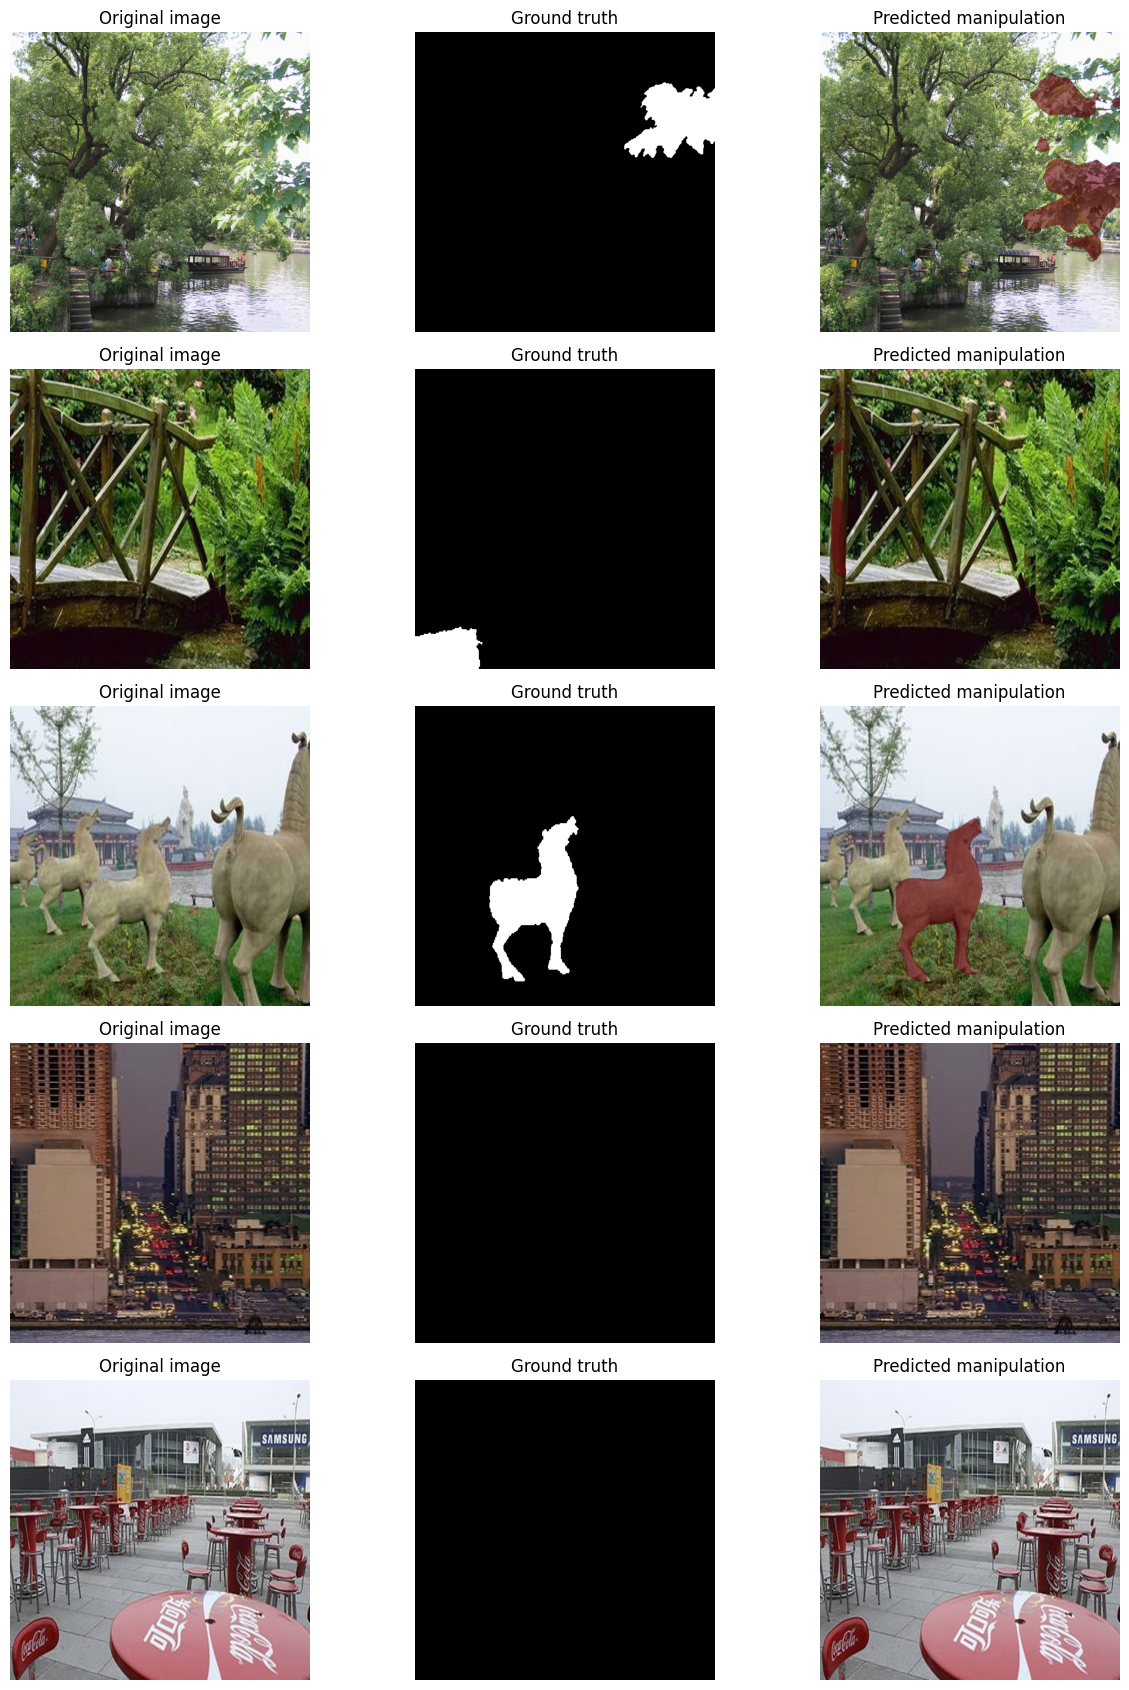

In [ ]:
# Visualize original images, ground-truth masks, and predicted manipulation masks

fig, axes = plt.subplots(len(selected_indices), 3, figsize=(13, 17))

model.eval()

for row, index in enumerate(selected_indices):
    record = val_records[index]
    sample = val_dataset[index]

    image = Image.open(record["image_path"]).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    ground_truth = sample["mask"].squeeze().numpy()

    pixel_values = sample["pixel_values"].unsqueeze(0).to(DEVICE)

    with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(pixel_values)

    probability = torch.sigmoid(logits.float()).squeeze().cpu().numpy()
    prediction = probability >= 0.5

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Original image")

    axes[row, 1].imshow(ground_truth, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(np.ma.masked_where(~prediction, prediction), cmap="Reds", alpha=0.6, vmin=0, vmax=1)
    axes[row, 2].set_title("Predicted manipulation")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Threshold optimization

The best model checkpoint was selected using validation Dice/F1 at a fixed threshold of 0.5, achieving a score of **0.8659**.

After training, the segmentation threshold was optimized on the CASIA v2 validation set. Thresholds from 0.1 to 0.9 were evaluated, with **0.7** achieving the highest validation Dice/F1 of **0.8666**.

This threshold was subsequently used for evaluation on Columbia and COVERAGE. No additional model training was performed during threshold optimization.

In [ ]:
# Find the optimal segmentation threshold using validation Dice/F1

@torch.inference_mode()
def find_best_threshold(model, loader):
    model.eval()

    thresholds = torch.arange(1, 10, device=DEVICE).float() / 10
    tp = torch.zeros(len(thresholds), device=DEVICE)
    fp = torch.zeros(len(thresholds), device=DEVICE)
    fn = torch.zeros(len(thresholds), device=DEVICE)

    for batch in tqdm(loader, desc="Threshold optimization"):
        images = batch["pixel_values"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True).bool()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        probabilities = torch.sigmoid(logits.float())
        predictions = probabilities.unsqueeze(0) >= thresholds[:, None, None, None, None]
        targets = masks.unsqueeze(0)

        tp += (predictions & targets).sum(dim=(1, 2, 3, 4))
        fp += (predictions & ~targets).sum(dim=(1, 2, 3, 4))
        fn += (~predictions & targets).sum(dim=(1, 2, 3, 4))

    dice_scores = 2 * tp / (2 * tp + fp + fn + 1e-8)
    best_index = dice_scores.argmax().item()

    return thresholds.cpu().numpy(), dice_scores.cpu().numpy(), best_index

In [ ]:
# Evaluate candidate thresholds and select the best one

thresholds, dice_scores, best_index = find_best_threshold(model, val_loader)

BEST_THRESHOLD = float(thresholds[best_index])

for threshold, dice in zip(thresholds, dice_scores):
    print(f"Threshold: {threshold:.1f} | Dice/F1: {dice:.4f}")

print(f"\nBest threshold: {BEST_THRESHOLD:.1f}")
print(f"Best Dice/F1: {dice_scores[best_index]:.4f}")

Threshold: 0.1 | Dice/F1: 0.8560
Threshold: 0.2 | Dice/F1: 0.8625
Threshold: 0.3 | Dice/F1: 0.8646
Threshold: 0.4 | Dice/F1: 0.8656
Threshold: 0.5 | Dice/F1: 0.8659
Threshold: 0.6 | Dice/F1: 0.8665
Threshold: 0.7 | Dice/F1: 0.8666
Threshold: 0.8 | Dice/F1: 0.8635
Threshold: 0.9 | Dice/F1: 0.8557

Best threshold: 0.7
Best Dice/F1: 0.8666


## Threshold visualization

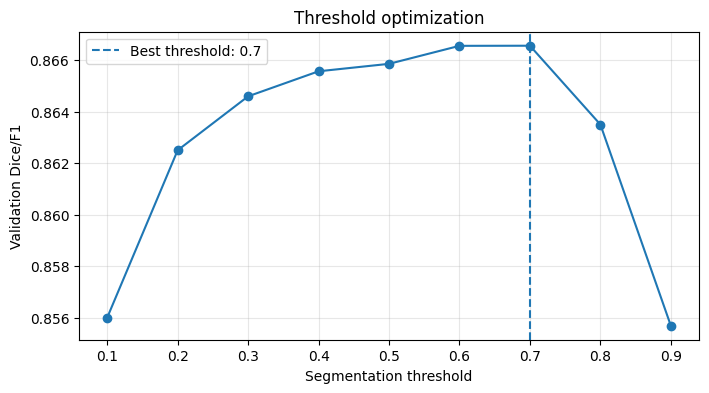

In [ ]:
# Visualize validation Dice/F1 across segmentation thresholds

plt.figure(figsize=(8, 4))
plt.plot(thresholds, dice_scores, marker="o")
plt.axvline(BEST_THRESHOLD, linestyle="--", label=f"Best threshold: {BEST_THRESHOLD:.1f}")

plt.xlabel("Segmentation threshold")
plt.ylabel("Validation Dice/F1")
plt.title("Threshold optimization")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# External evaluation

## Columbia dataset

In [ ]:
# Download the Columbia Uncompressed Image Splicing Dataset from its official Dropbox mirror

from pathlib import Path
import requests
import zipfile

EXTERNAL_ROOT = Path("/content/external")
COLUMBIA_ROOT = EXTERNAL_ROOT / "columbia"
COLUMBIA_ARCHIVE = EXTERNAL_ROOT / "columbia.zip"

EXTERNAL_ROOT.mkdir(parents=True, exist_ok=True)

COLUMBIA_URL = "https://www.dropbox.com/scl/fo/1stuwnzt71fpxk7jjdyag/ADolaxmm0evKaKwq2IqfNVM?rlkey=xxrhrryajl6dznf3siikyyjig&dl=1"

if not COLUMBIA_ARCHIVE.exists():
    with requests.get(COLUMBIA_URL, stream=True, timeout=120) as response:
        response.raise_for_status()

        with open(COLUMBIA_ARCHIVE, "wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)

if not zipfile.is_zipfile(COLUMBIA_ARCHIVE):
    raise RuntimeError("Dropbox did not return a ZIP archive. Use the official download page.")

print(f"Archive size: {COLUMBIA_ARCHIVE.stat().st_size / 1024**2:.1f} MB")

Archive size: 382.8 MB


## Dataset extraction

In [ ]:
# Extract the Columbia dataset and any nested TAR archives

import tarfile

COLUMBIA_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(COLUMBIA_ARCHIVE) as archive:
    archive.extractall(COLUMBIA_ROOT)

archives = [
    path for path in COLUMBIA_ROOT.rglob("*")
    if path.is_file() and path.name.lower().endswith((".tar.bz2", ".tar.gz", ".tar", ".tbz2", ".tgz"))
]

for archive_path in archives:
    output_dir = archive_path.parent / archive_path.name.split(".tar")[0].removesuffix(".tbz2").removesuffix(".tgz")
    output_dir.mkdir(parents=True, exist_ok=True)

    with tarfile.open(archive_path, "r:*") as archive:
        archive.extractall(output_dir, filter="data")

print("Extraction completed")
print("Nested archives:", len(archives))

Extraction completed
Nested archives: 2


## Dataset inspection

In [ ]:
# Inspect the Columbia directory structure and file extensions

from collections import Counter

directories = sorted(path for path in COLUMBIA_ROOT.rglob("*") if path.is_dir())
files = [path for path in COLUMBIA_ROOT.rglob("*") if path.is_file()]

print("Directories:")
for path in directories:
    if len(path.relative_to(COLUMBIA_ROOT).parts) <= 3:
        print(" ", path.relative_to(COLUMBIA_ROOT))

print("\nFile extensions:")
print(Counter(path.suffix.lower() for path in files))

print("\nTotal files:", len(files))

Directories:
  4cam_auth
  4cam_auth/4cam_auth
  4cam_auth/4cam_auth/edgemask
  4cam_splc
  4cam_splc/4cam_splc
  4cam_splc/4cam_splc/edgemask

File extensions:
Counter({'.jpg': 728, '.tif': 363, '.db': 4, '.bz2': 2, '.txt': 1})

Total files: 1098


In [ ]:
# Inspect sample filenames and identify potential ground-truth masks

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_files = sorted(path for path in files if path.suffix.lower() in image_extensions)
mask_candidates = [path for path in image_files if any(term in str(path).lower() for term in ["mask", "gt", "ground", "edge"])]

print("Sample image files:")
for path in image_files[:15]:
    print(path.relative_to(COLUMBIA_ROOT))

print("\nPotential ground-truth files:")
for path in mask_candidates[:15]:
    print(path.relative_to(COLUMBIA_ROOT))

print("\nImage files:", len(image_files))
print("Potential masks:", len(mask_candidates))

Sample image files:
4cam_auth/4cam_auth/canong3_02_sub_01.tif
4cam_auth/4cam_auth/canong3_02_sub_02.tif
4cam_auth/4cam_auth/canong3_02_sub_03.tif
4cam_auth/4cam_auth/canong3_02_sub_04.tif
4cam_auth/4cam_auth/canong3_02_sub_05.tif
4cam_auth/4cam_auth/canong3_02_sub_06.tif
4cam_auth/4cam_auth/canong3_02_sub_07.tif
4cam_auth/4cam_auth/canong3_02_sub_08.tif
4cam_auth/4cam_auth/canong3_02_sub_09.tif
4cam_auth/4cam_auth/canong3_05_sub_01.tif
4cam_auth/4cam_auth/canong3_05_sub_02.tif
4cam_auth/4cam_auth/canong3_05_sub_03.tif
4cam_auth/4cam_auth/canong3_05_sub_04.tif
4cam_auth/4cam_auth/canong3_05_sub_05.tif
4cam_auth/4cam_auth/canong3_05_sub_06.tif

Potential ground-truth files:
4cam_auth/4cam_auth/edgemask/canong3_02_sub_01_edgemask.jpg
4cam_auth/4cam_auth/edgemask/canong3_02_sub_01_edgemask_3.jpg
4cam_auth/4cam_auth/edgemask/canong3_02_sub_02_edgemask.jpg
4cam_auth/4cam_auth/edgemask/canong3_02_sub_02_edgemask_3.jpg
4cam_auth/4cam_auth/edgemask/canong3_02_sub_03_edgemask.jpg
4cam_auth/4cam_

## Ground-truth inspection

In [ ]:
# Match Columbia spliced images with their two edge-mask versions

SPLICE_DIR = COLUMBIA_ROOT / "4cam_splc" / "4cam_splc"
AUTH_DIR = COLUMBIA_ROOT / "4cam_auth" / "4cam_auth"
EDGE_DIR = SPLICE_DIR / "edgemask"

spliced_images = sorted(SPLICE_DIR.glob("*.tif"))
authentic_images = sorted(AUTH_DIR.glob("*.tif"))

pairs = [(p, EDGE_DIR / f"{p.stem}_edgemask.jpg", EDGE_DIR / f"{p.stem}_edgemask_3.jpg") for p in spliced_images]

print("Authentic:", len(authentic_images))
print("Spliced:", len(spliced_images))
print("Missing edge masks:", sum(not m.exists() for _, m, _ in pairs))
print("Missing edge masks (_3):", sum(not m.exists() for _, _, m in pairs))

Authentic: 183
Spliced: 180
Missing edge masks: 0
Missing edge masks (_3): 0


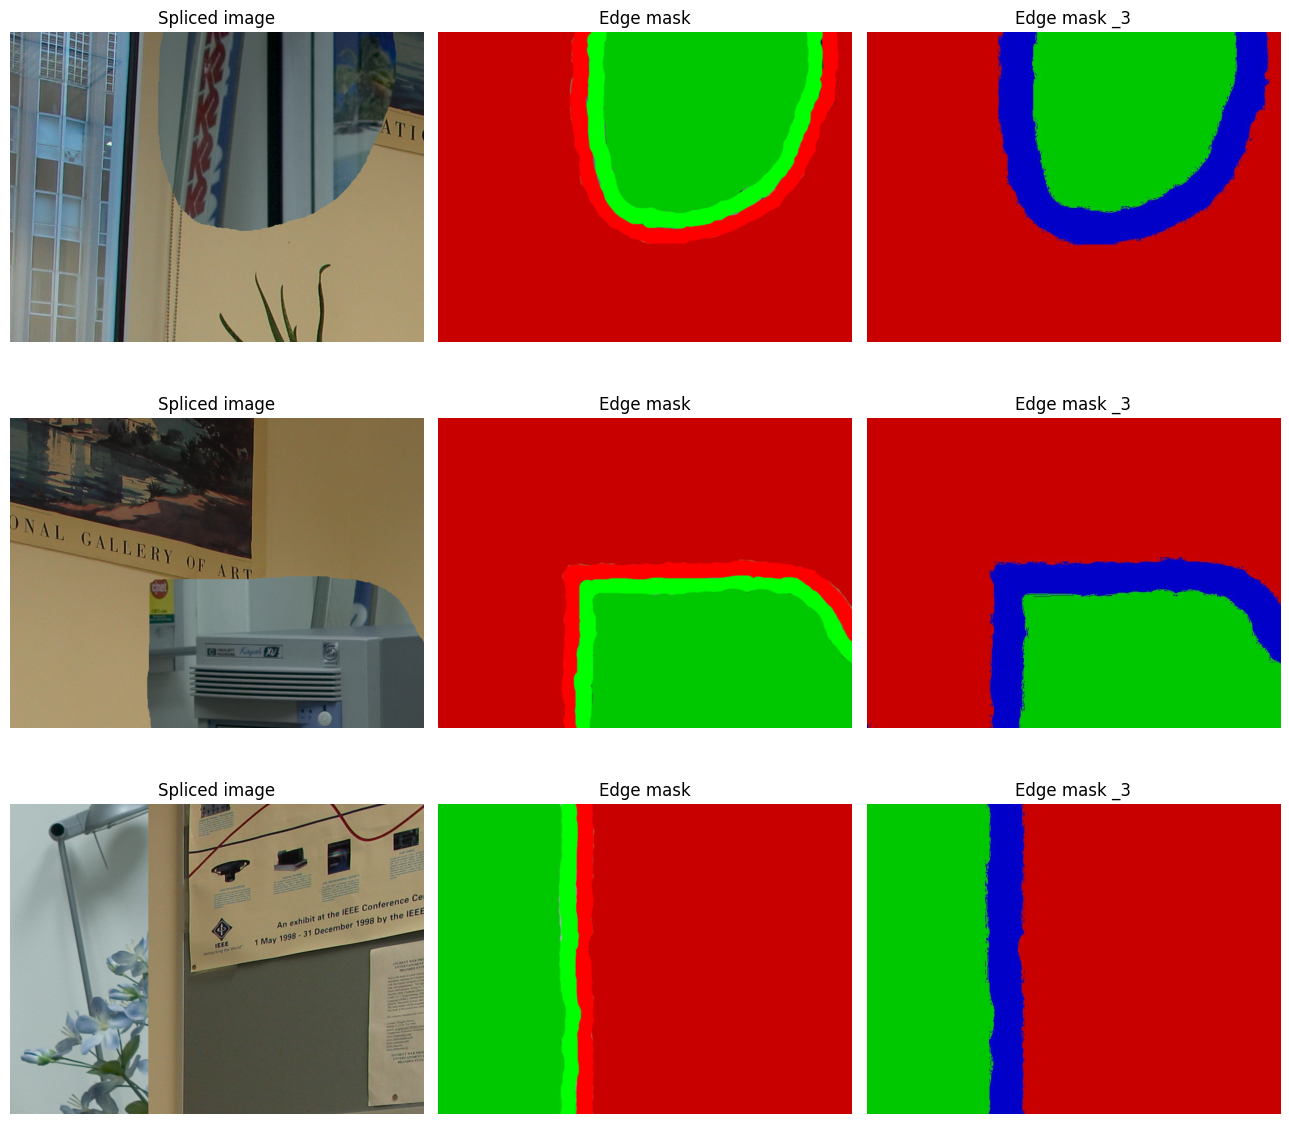

In [ ]:
# Compare spliced images with both ground-truth edge-mask versions

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for row, (image_path, mask_path, mask3_path) in enumerate(pairs[:3]):
    for col, (path, title) in enumerate(zip([image_path, mask_path, mask3_path], ["Spliced image", "Edge mask", "Edge mask _3"])):
        with Image.open(path) as image:
            axes[row, col].imshow(image.copy())
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Ground-truth conversion

In [ ]:
# Convert Columbia color annotations into binary masks and valid-pixel masks

def decode_columbia_mask(mask_path, image_size=IMAGE_SIZE):
    with Image.open(mask_path) as image:
        rgb = np.asarray(image.convert("RGB").resize((image_size, image_size), Image.Resampling.NEAREST)).astype(np.int16)

    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]

    manipulated = (green > red + 30) & (green > blue + 30)
    authentic = (red > green + 30) & (red > blue + 30)
    valid = manipulated | authentic

    return manipulated.astype(np.float32), valid.astype(np.float32)

Manipulated area: 23.99%
Valid pixels: 86.34%
Excluded boundary: 13.66%


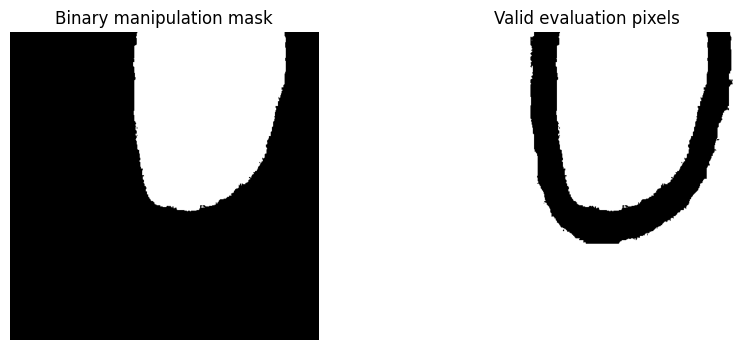

In [ ]:
# Check the converted mask and the fraction of excluded boundary pixels

mask, valid = decode_columbia_mask(pairs[0][2])

print(f"Manipulated area: {mask.mean() * 100:.2f}%")
print(f"Valid pixels: {valid.mean() * 100:.2f}%")
print(f"Excluded boundary: {(1 - valid.mean()) * 100:.2f}%")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
plt.title("Binary manipulation mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(valid, cmap="gray", vmin=0, vmax=1)
plt.title("Valid evaluation pixels")
plt.axis("off")
plt.show()

## Columbia dataset loader

In [ ]:
# Create evaluation records for all authentic and spliced Columbia images

columbia_records = [{"image_path": path, "mask_path": mask3_path, "label": 1} for path, _, mask3_path in pairs]
columbia_records += [{"image_path": path, "mask_path": None, "label": 0} for path in authentic_images]

assert len(columbia_records) == 363
assert all(record["mask_path"].exists() for record in columbia_records if record["label"] == 1)

print("Total:", len(columbia_records))
print("Spliced:", sum(record["label"] for record in columbia_records))
print("Authentic:", sum(not record["label"] for record in columbia_records))

Total: 363
Spliced: 180
Authentic: 183


In [ ]:
# Define a Columbia dataset with binary masks and ignored boundary pixels

from torch.utils.data import Dataset, DataLoader

class ColumbiaDataset(Dataset):
    def __init__(self, records, processor, image_size=512):
        self.records = records
        self.processor = processor
        self.image_size = image_size

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        with Image.open(record["image_path"]) as image:
            image = image.convert("RGB").resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)

        if record["mask_path"] is None:
            mask = np.zeros((self.image_size, self.image_size), dtype=np.float32)
            valid = np.ones((self.image_size, self.image_size), dtype=np.float32)
        else:
            mask, valid = decode_columbia_mask(record["mask_path"], self.image_size)

        pixel_values = self.processor(images=image, return_tensors="pt", do_resize=False, do_center_crop=False)["pixel_values"].squeeze(0)

        return {
            "pixel_values": pixel_values,
            "mask": torch.from_numpy(mask).unsqueeze(0),
            "valid": torch.from_numpy(valid).unsqueeze(0),
            "label": record["label"]
        }

In [ ]:
# Prepare the Columbia evaluation data loader

columbia_dataset = ColumbiaDataset(columbia_records, processor, IMAGE_SIZE)
columbia_loader = DataLoader(columbia_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

batch = next(iter(columbia_loader))

print("Images:", batch["pixel_values"].shape)
print("Masks:", batch["mask"].shape)
print("Valid pixels:", batch["valid"].shape)

Images: torch.Size([4, 3, 512, 512])
Masks: torch.Size([4, 1, 512, 512])
Valid pixels: torch.Size([4, 1, 512, 512])


## Columbia evaluation

The model was evaluated on the Columbia Uncompressed Image Splicing Dataset without additional training or threshold tuning.

**Evaluation protocol:**
- **Dataset:** 363 images (180 spliced, 183 authentic).
- **Input resolution:** 512 × 512 pixels.
- **Segmentation threshold:** 0.7, selected on CASIA v2 validation.
- **Ground truth:** Color-coded `_edgemask_3.jpg` annotations were converted into binary manipulation masks.
- **Ignored pixels:** Ambiguous annotation regions were excluded from metric calculations using a valid-pixel mask.
- **Metrics:** Micro Dice/F1 and Micro IoU, aggregated across all valid pixels.

**Results:**
- Micro Dice/F1: **0.9225**
- Micro IoU: **0.8562**
- Mean Dice/F1 on spliced images: **0.9292**
- Mean false-positive area on authentic images: **0.3513%**

These results reflect the evaluation protocol described above and should not be directly compared with results obtained using different annotation processing or evaluation procedures.

In [ ]:
# Evaluate pixel-level Dice/F1 and IoU while excluding uncertain boundary pixels

from tqdm.auto import tqdm

@torch.inference_mode()
def evaluate_external(model, loader, threshold=0.7):
    model.eval()

    total_tp, total_fp, total_fn = 0, 0, 0
    tampered_dice = []
    authentic_false_area = []

    for batch in tqdm(loader, desc="External evaluation"):
        images = batch["pixel_values"].to(DEVICE, non_blocking=True)
        targets = batch["mask"].to(DEVICE, non_blocking=True).bool()
        valid = batch["valid"].to(DEVICE, non_blocking=True).bool()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        predictions = torch.sigmoid(logits.float()) >= threshold

        tp = (predictions & targets & valid).sum(dim=(1, 2, 3)).cpu().numpy()
        fp = (predictions & ~targets & valid).sum(dim=(1, 2, 3)).cpu().numpy()
        fn = (~predictions & targets & valid).sum(dim=(1, 2, 3)).cpu().numpy()
        valid_counts = valid.sum(dim=(1, 2, 3)).cpu().numpy()
        labels = batch["label"].numpy()

        total_tp += int(tp.sum())
        total_fp += int(fp.sum())
        total_fn += int(fn.sum())

        for i, label in enumerate(labels):
            if label == 1:
                dice = 2 * tp[i] / (2 * tp[i] + fp[i] + fn[i] + 1e-8)
                tampered_dice.append(float(dice))
            else:
                authentic_false_area.append(float(fp[i] / max(valid_counts[i], 1)))

    micro_dice = 2 * total_tp / (2 * total_tp + total_fp + total_fn + 1e-8)
    micro_iou = total_tp / (total_tp + total_fp + total_fn + 1e-8)

    results = {
        "Micro Dice/F1": micro_dice,
        "Micro IoU": micro_iou,
        "Tampered mean Dice/F1": np.mean(tampered_dice),
        "Authentic false-positive area (%)": np.mean(authentic_false_area) * 100
    }

    return results

In [ ]:
# Run zero-shot evaluation on Columbia using the fixed validation threshold

columbia_results = evaluate_external(model, columbia_loader, threshold=BEST_THRESHOLD)

for metric, value in columbia_results.items():
    print(f"{metric}: {value:.4f}")

Micro Dice/F1: 0.9225
Micro IoU: 0.8562
Tampered mean Dice/F1: 0.9292
Authentic false-positive area (%): 0.3513


## Prediction analysis

In [ ]:
# Calculate Dice/F1 for each manipulated image and false-positive area for authentic images

@torch.inference_mode()
def score_columbia_samples(model, loader, threshold=BEST_THRESHOLD):
    model.eval()
    results = []

    for batch in tqdm(loader, desc="Per-image evaluation"):
        images = batch["pixel_values"].to(DEVICE)
        targets = batch["mask"].to(DEVICE).bool()
        valid = batch["valid"].to(DEVICE).bool()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        predictions = torch.sigmoid(logits.float()) >= threshold

        tp = (predictions & targets & valid).sum(dim=(1, 2, 3)).cpu().numpy()
        fp = (predictions & ~targets & valid).sum(dim=(1, 2, 3)).cpu().numpy()
        fn = (~predictions & targets & valid).sum(dim=(1, 2, 3)).cpu().numpy()
        valid_pixels = valid.sum(dim=(1, 2, 3)).cpu().numpy()

        for i, label in enumerate(batch["label"].tolist()):
            results.append({
                "index": len(results),
                "label": label,
                "dice": float(2 * tp[i] / (2 * tp[i] + fp[i] + fn[i] + 1e-8)) if label == 1 else None,
                "false_area": float(fp[i] / max(valid_pixels[i], 1))
            })

    return results

columbia_scores = score_columbia_samples(model, columbia_loader)

tampered_scores = sorted([r for r in columbia_scores if r["label"] == 1], key=lambda r: r["dice"])
authentic_scores = sorted([r for r in columbia_scores if r["label"] == 0], key=lambda r: r["false_area"], reverse=True)

print("Worst tampered Dice:", [round(r["dice"], 4) for r in tampered_scores[:5]])
print("Best tampered Dice:", [round(r["dice"], 4) for r in tampered_scores[-5:]])
print("Tampered images with Dice < 0.5:", sum(r["dice"] < 0.5 for r in tampered_scores))
print("Worst authentic false-positive area:", round(authentic_scores[0]["false_area"] * 100, 2), "%")

Worst tampered Dice: [0.0, 0.0, 0.0, 0.0, 0.0001]
Best tampered Dice: [1.0, 1.0, 1.0, 1.0, 1.0]
Tampered images with Dice < 0.5: 10
Worst authentic false-positive area: 18.51 %


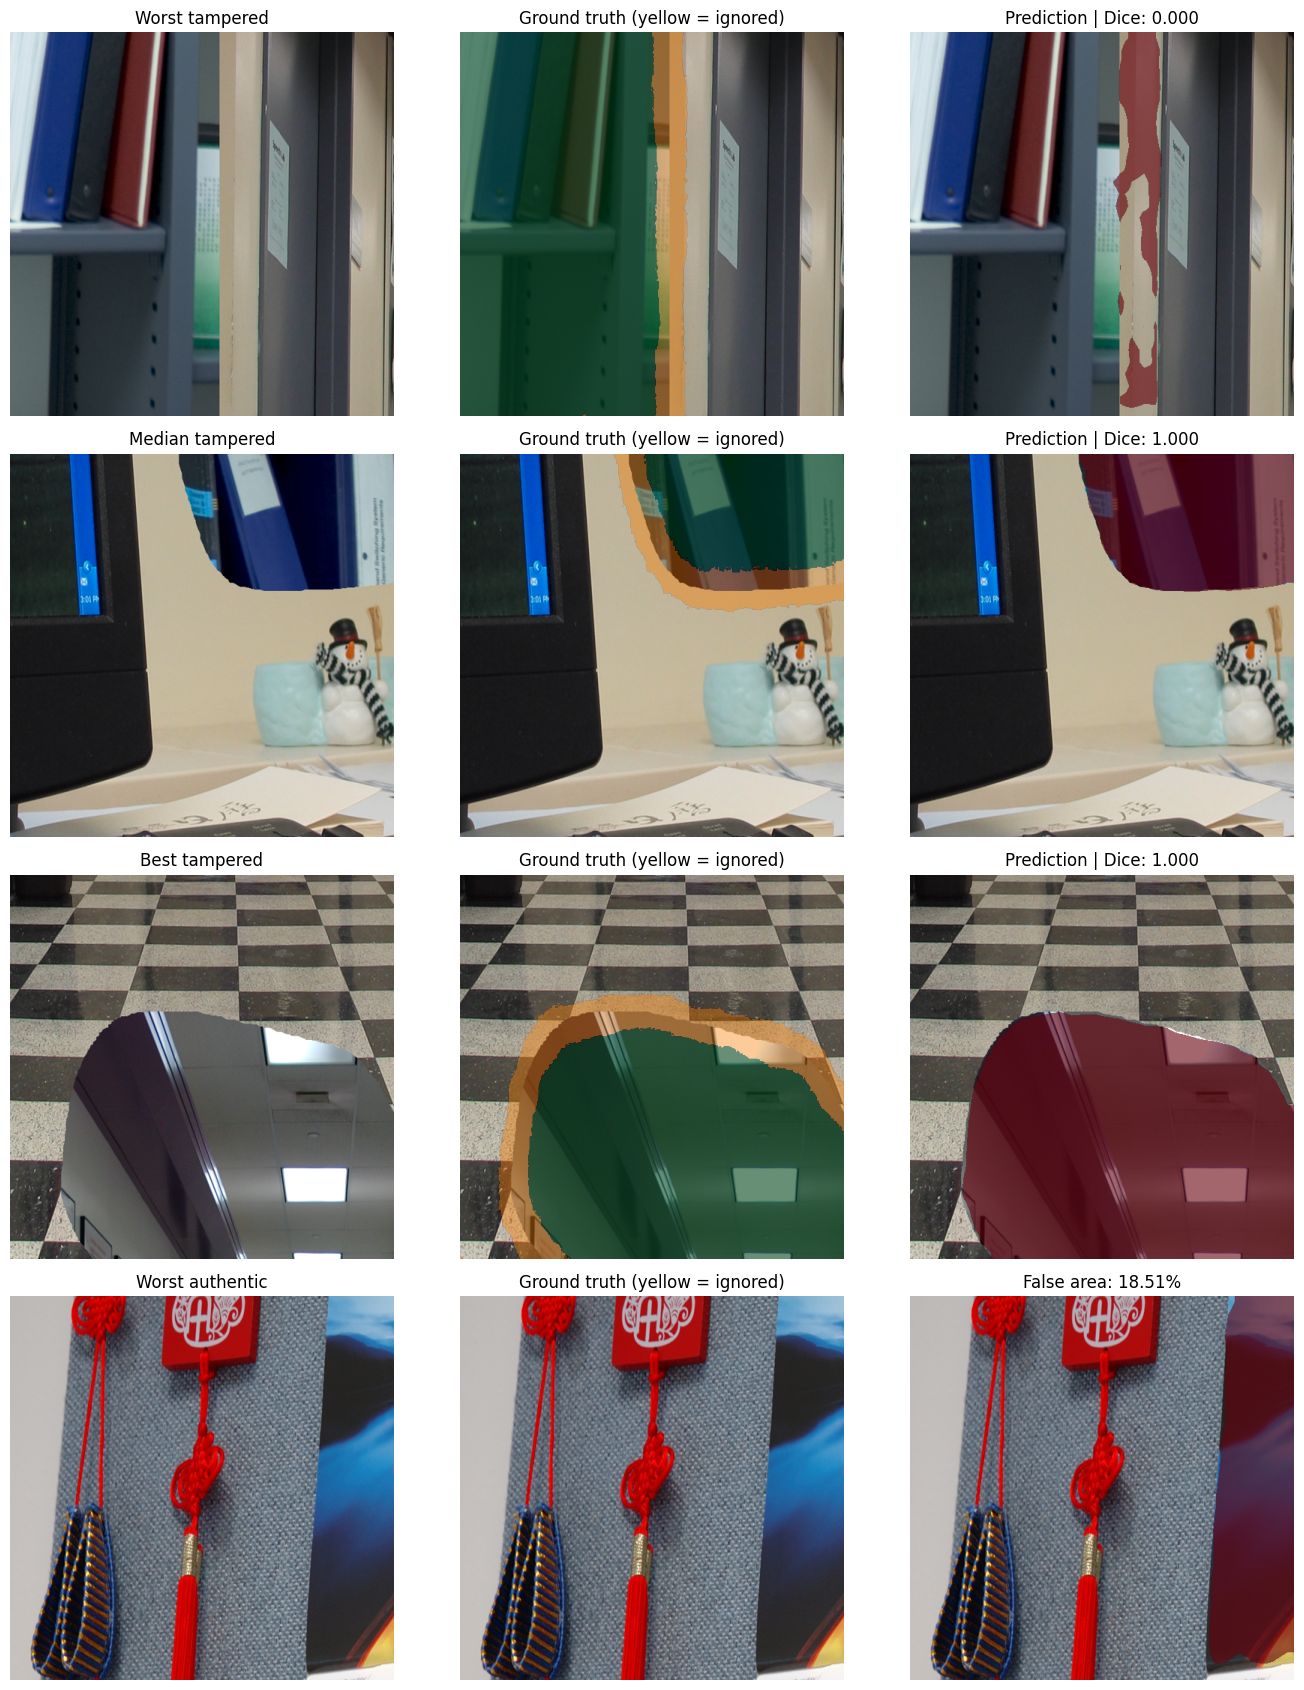

In [ ]:
# Visualize the worst, median, and best tampered predictions and the worst authentic prediction

selected = [
    ("Worst tampered", tampered_scores[0]),
    ("Median tampered", tampered_scores[len(tampered_scores) // 2]),
    ("Best tampered", tampered_scores[-1]),
    ("Worst authentic", authentic_scores[0])
]

fig, axes = plt.subplots(len(selected), 3, figsize=(14, 17))

for row, (description, result) in enumerate(selected):
    sample = columbia_dataset[result["index"]]
    record = columbia_records[result["index"]]

    with Image.open(record["image_path"]) as image:
        image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))

    gt = sample["mask"].squeeze().numpy()
    valid = sample["valid"].squeeze().numpy()

    with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(sample["pixel_values"].unsqueeze(0).to(DEVICE))

    prediction = (torch.sigmoid(logits.float()).squeeze().cpu().numpy() >= BEST_THRESHOLD)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(description)

    axes[row, 1].imshow(image)
    axes[row, 1].imshow(np.ma.masked_where(gt == 0, gt), cmap="Greens", alpha=0.6, vmin=0, vmax=1)
    axes[row, 1].imshow(np.ma.masked_where(valid == 1, 1 - valid), cmap="Wistia", alpha=0.4, vmin=0, vmax=1)
    axes[row, 1].set_title("Ground truth (yellow = ignored)")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(np.ma.masked_where(~prediction, prediction), cmap="Reds", alpha=0.6, vmin=0, vmax=1)
    axes[row, 2].set_title(f"Prediction | Dice: {result['dice']:.3f}" if result["label"] == 1 else f"False area: {result['false_area'] * 100:.2f}%")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## COVERAGE dataset

In [ ]:
# Upload the COVERAGE archive to the Colab runtime

from google.colab import files
from pathlib import Path

uploaded = files.upload()
COVERAGE_ARCHIVE = Path("/content") / next(iter(uploaded))

print("Archive:", COVERAGE_ARCHIVE.name)
print(f"Size: {COVERAGE_ARCHIVE.stat().st_size / 1024**2:.1f} MB")

Saving COVERAGE.zip to COVERAGE.zip
Archive: COVERAGE.zip
Size: 140.4 MB


## Dataset extraction

In [ ]:
# Extract the COVERAGE archive to the Colab runtime

import shutil

COVERAGE_ROOT = Path("/content/external/coverage")
COVERAGE_ROOT.mkdir(parents=True, exist_ok=True)

shutil.unpack_archive(str(COVERAGE_ARCHIVE), str(COVERAGE_ROOT))

print("COVERAGE extracted successfully")

COVERAGE extracted successfully


## Dataset inspection

In [ ]:
# Inspect COVERAGE directories and sample files

from collections import Counter

coverage_files = sorted(path for path in COVERAGE_ROOT.rglob("*") if path.is_file())

print("Extensions:", Counter(path.suffix.lower() for path in coverage_files))
print("Total files:", len(coverage_files))

for path in coverage_files[:25]:
    print(path.relative_to(COVERAGE_ROOT))

Extensions: Counter({'.tif': 499, '.mat': 4, '.txt': 3})
Total files: 506
COVERAGE/image/1.tif
COVERAGE/image/10.tif
COVERAGE/image/100.tif
COVERAGE/image/100t.tif
COVERAGE/image/10t.tif
COVERAGE/image/11.tif
COVERAGE/image/11t.tif
COVERAGE/image/12.tif
COVERAGE/image/12t.tif
COVERAGE/image/13.tif
COVERAGE/image/13t.tif
COVERAGE/image/14.tif
COVERAGE/image/14t.tif
COVERAGE/image/15.tif
COVERAGE/image/15t.tif
COVERAGE/image/16.tif
COVERAGE/image/16t.tif
COVERAGE/image/17.tif
COVERAGE/image/17t.tif
COVERAGE/image/18.tif
COVERAGE/image/18t.tif
COVERAGE/image/19.tif
COVERAGE/image/19t.tif
COVERAGE/image/1t.tif
COVERAGE/image/2.tif


In [ ]:
# Remove the uploaded archive to free Colab disk space

COVERAGE_ARCHIVE.unlink()
print("Archive removed")

Archive removed


## File structure inspection

In [ ]:
# Group COVERAGE files by directory and inspect representative filenames

from collections import defaultdict

files_by_directory = defaultdict(list)

for path in coverage_files:
    files_by_directory[str(path.parent.relative_to(COVERAGE_ROOT))].append(path.name)

for directory, filenames in sorted(files_by_directory.items()):
    print(f"\n{directory} — {len(filenames)} files")
    print("Samples:", sorted(filenames)[:12])


. — 1 files
Samples: ['___All_Errors.txt']

COVERAGE — 1 files
Samples: ['readme.txt']

COVERAGE/image — 199 files
Samples: ['1.tif', '10.tif', '100.tif', '100t.tif', '10t.tif', '11.tif', '11t.tif', '12.tif', '12t.tif', '13.tif', '13t.tif', '14.tif']

COVERAGE/label — 4 files
Samples: ['FEA.mat', 'TFlabel.mat', 'Tlevel.mat', 'fPSNR.mat']

COVERAGE/mask — 300 files
Samples: ['100copy.tif', '100forged.tif', '100paste.tif', '10copy.tif', '10forged.tif', '10paste.tif', '11copy.tif', '11forged.tif', '11paste.tif', '12copy.tif', '12forged.tif', '12paste.tif']

__COVERAGE/image — 1 files
Samples: ['46t.tif_Error.txt']


## Annotation inspection

In [ ]:
# Inspect dataset documentation and TIFF annotation formats

for path in sorted(COVERAGE_ROOT.rglob("*.txt")):
    print(f"\n--- {path.name} ---")
    print(path.read_text(errors="replace")[:2000])

candidate_masks = [p for p in coverage_files if p.suffix.lower() == ".tif" and any(term in str(p.parent).lower() for term in ["mask", "gt", "forged"])]

print("\nCandidate mask files:", len(candidate_masks))

for path in candidate_masks[:5]:
    with Image.open(path) as image:
        array = np.asarray(image)
    print(path.relative_to(COVERAGE_ROOT), "Shape:", array.shape, "Values:", np.unique(array)[:20])


--- readme.txt ---
% Copy-Move Forgery Database with Similar but Genuine Objects %

The Copy-Move Forgery Database with Similar but Genuine Objects (COVERAGE) accompanies the following publication: 
"COVERAGE - A NOVEL DATABASE FOR COPY-MOVE FORGERY DETECTION," IEEE International Conference on Image Processing (ICIP), 2016

To use:
All data is subject to copyright and may only be used for non-commercial research. 

In case of use, please cite our publication:
B. Wen, Y. Zhu, R. Subramanian, T. Ng, X. Shen, and S. Winkler, "COVERAGE - A Novel Database for Copy-Move Forgery Detection," in Proc. IEEE Int. Conf. Image Processing (ICIP), 2016.

Bibtex:
@inproceedings{wen2016,
  author={Wen, Bihan and Zhu, Ye and Subramanian, Ramanathan and Ng, Tian-Tsong and Shen, Xuanjing and Winkler, Stefan},
  title={COVERAGE - A NOVEL DATABASE FOR COPY-MOVE FORGERY DETECTION},
  year={2016},
  booktitle={IEEE International Conference on Image processing (ICIP)}
}

%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%

## COVERAGE file pairing

In [ ]:
# Match authentic images, manipulated images, and ground-truth masks

COVERAGE_DATA = COVERAGE_ROOT / "COVERAGE"
COVERAGE_IMAGES = COVERAGE_DATA / "image"
COVERAGE_MASKS = COVERAGE_DATA / "mask"

coverage_ids = []
missing_files = []

for index in range(1, 101):
    required = [
        COVERAGE_IMAGES / f"{index}.tif",
        COVERAGE_IMAGES / f"{index}t.tif",
        COVERAGE_MASKS / f"{index}forged.tif"
    ]

    if all(path.exists() for path in required):
        coverage_ids.append(index)
    else:
        missing_files.append((index, [path.name for path in required if not path.exists()]))

print("Complete pairs:", len(coverage_ids))
print("Missing files:", missing_files)

Complete pairs: 99
Missing files: [(46, ['46t.tif'])]


## Mask visualization

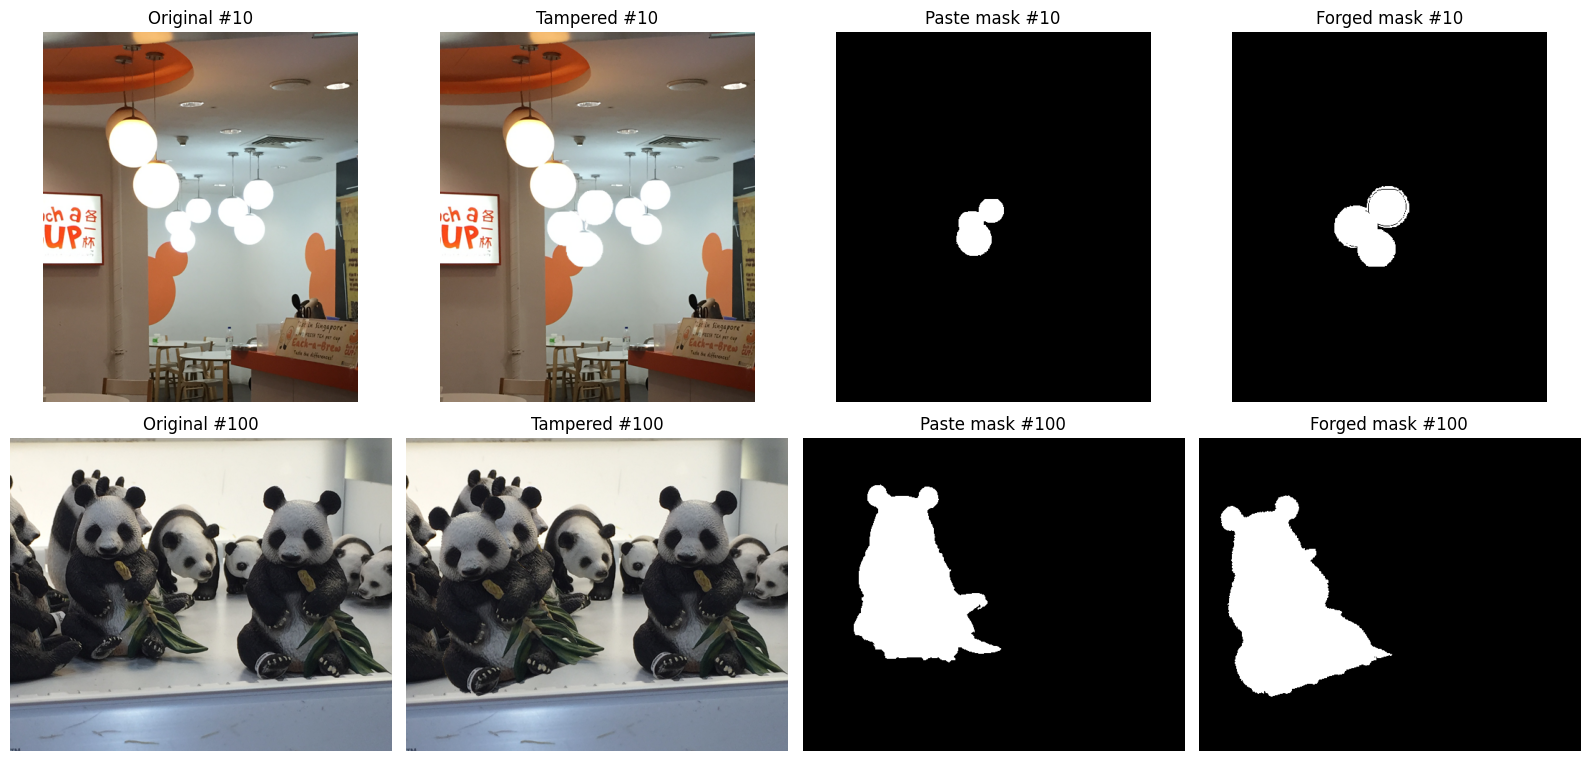

In [ ]:
# Compare original, tampered, and annotated regions for selected COVERAGE samples

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, index in enumerate([10, 100]):
    paths = [
        COVERAGE_IMAGES / f"{index}.tif",
        COVERAGE_IMAGES / f"{index}t.tif",
        COVERAGE_MASKS / f"{index}paste.tif",
        COVERAGE_MASKS / f"{index}forged.tif"
    ]

    for col, (path, title) in enumerate(zip(paths, ["Original", "Tampered", "Paste mask", "Forged mask"])):
        with Image.open(path) as image:
            axes[row, col].imshow(image.copy(), cmap="gray" if col >= 2 else None)
        axes[row, col].set_title(f"{title} #{index}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## COVERAGE dataset loader

In [ ]:
# Build COVERAGE evaluation records using complete image pairs

coverage_records = []

for index in coverage_ids:
    coverage_records.append({"image_path": COVERAGE_IMAGES / f"{index}t.tif", "mask_path": COVERAGE_MASKS / f"{index}forged.tif", "label": 1})
    coverage_records.append({"image_path": COVERAGE_IMAGES / f"{index}.tif", "mask_path": None, "label": 0})

print("Total:", len(coverage_records))
print("Tampered:", sum(record["label"] for record in coverage_records))
print("Authentic:", sum(not record["label"] for record in coverage_records))

Total: 198
Tampered: 99
Authentic: 99


In [ ]:
# Define a PyTorch dataset for COVERAGE evaluation

class CoverageDataset(Dataset):
    def __init__(self, records, processor, image_size=512):
        self.records = records
        self.processor = processor
        self.image_size = image_size

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        with Image.open(record["image_path"]) as image:
            image = image.convert("RGB").resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)

        if record["mask_path"] is None:
            mask = np.zeros((self.image_size, self.image_size), dtype=np.float32)
        else:
            with Image.open(record["mask_path"]) as annotation:
                annotation = annotation.convert("L").resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
                mask = (np.asarray(annotation) > 127).astype(np.float32)

        pixel_values = self.processor(images=image, return_tensors="pt", do_resize=False, do_center_crop=False)["pixel_values"].squeeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return {"pixel_values": pixel_values, "mask": mask, "valid": torch.ones_like(mask), "label": record["label"]}

## COVERAGE evaluation

The model was evaluated on the COVERAGE copy-move forgery dataset without additional training.

**Evaluation protocol:**
- **Dataset:** 99 complete image pairs (99 tampered and 99 authentic images).
- **Input resolution:** 512 × 512 pixels.
- **Segmentation threshold:** 0.7, selected on CASIA v2 validation.
- **Ground truth:** Binary `*forged.tif` masks for manipulated images; empty masks for authentic images.
- **Metrics:** Micro Dice/F1 and Micro IoU, aggregated across all evaluated pixels.

**Results:**
- Micro Dice/F1: **0.7237**
- Micro IoU: **0.5670**
- Mean Dice/F1 on tampered images: **0.7458**
- Mean false-positive area on authentic images: **2.1135%**

**Dataset limitation:** COVERAGE contains 100 image pairs, but the manipulated image `46t.tif` was missing from the downloaded archive. Therefore, only 99 complete pairs (198 images) were evaluated.

The results demonstrate cross-dataset performance under this evaluation protocol. COVERAGE was also inspected during development, so these results should not be presented as an untouched blind-test evaluation.

In [ ]:
# Create the COVERAGE data loader and evaluate the pretrained ForgeryLens model

coverage_dataset = CoverageDataset(coverage_records, processor, IMAGE_SIZE)
coverage_loader = DataLoader(coverage_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

coverage_results = evaluate_external(model, coverage_loader, threshold=BEST_THRESHOLD)

for metric, value in coverage_results.items():
    print(f"{metric}: {value:.4f}")

Micro Dice/F1: 0.7237
Micro IoU: 0.5670
Tampered mean Dice/F1: 0.7458
Authentic false-positive area (%): 2.1135


## COVERAGE error analysis

In [ ]:
# Rank COVERAGE images by segmentation quality and false-positive area

coverage_scores = score_columbia_samples(model, coverage_loader, threshold=BEST_THRESHOLD)

coverage_tampered = sorted([r for r in coverage_scores if r["label"] == 1], key=lambda r: r["dice"])
coverage_authentic = sorted([r for r in coverage_scores if r["label"] == 0], key=lambda r: r["false_area"], reverse=True)

print("Worst tampered images:")
for result in coverage_tampered[:5]:
    print(coverage_records[result["index"]]["image_path"].name, f"Dice: {result['dice']:.4f}")

print("\nTampered images with Dice < 0.5:", sum(r["dice"] < 0.5 for r in coverage_tampered))

print("\nWorst authentic images:")
for result in coverage_authentic[:5]:
    print(coverage_records[result["index"]]["image_path"].name, f"False area: {result['false_area'] * 100:.2f}%")

Worst tampered images:
8t.tif Dice: 0.0000
57t.tif Dice: 0.0000
61t.tif Dice: 0.0000
87t.tif Dice: 0.0000
91t.tif Dice: 0.0000

Tampered images with Dice < 0.5: 18

Worst authentic images:
72.tif False area: 23.39%
53.tif False area: 19.13%
60.tif False area: 13.47%
79.tif False area: 10.31%
28.tif False area: 8.66%


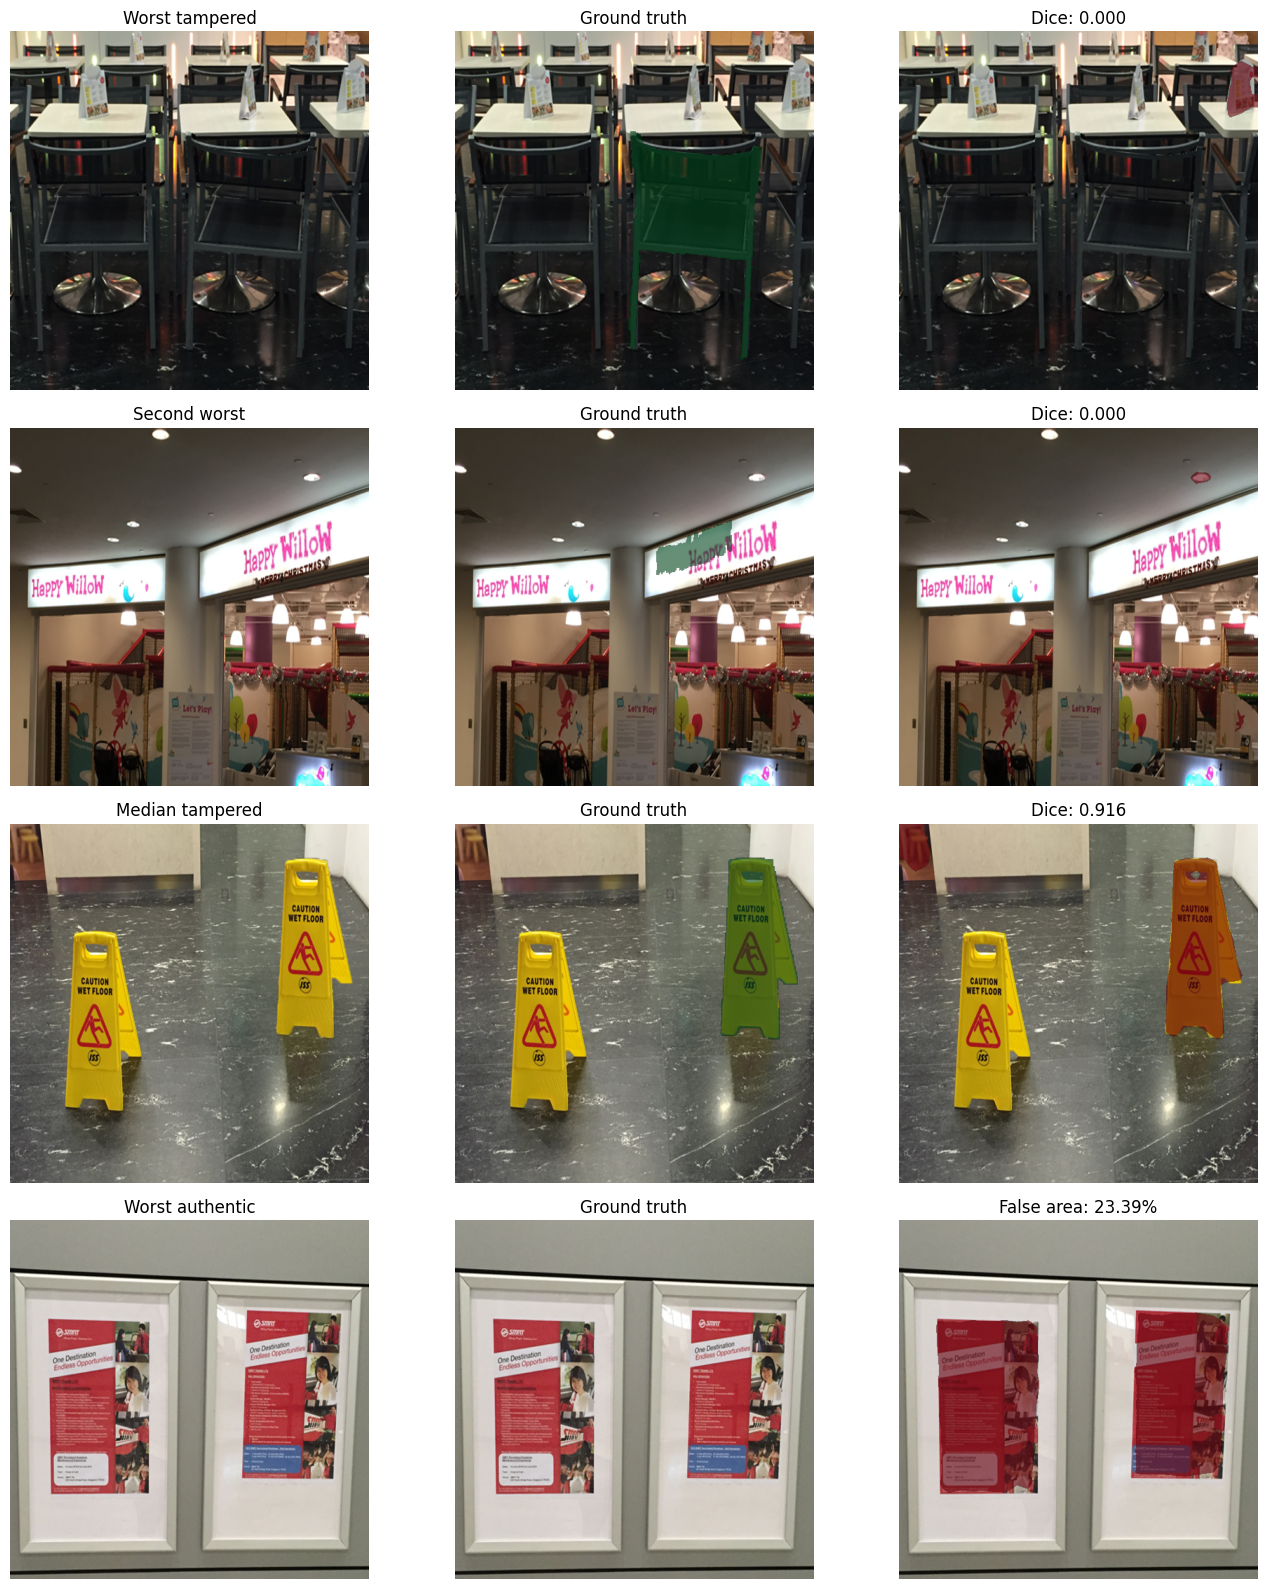

In [ ]:
# Visualize difficult COVERAGE examples and compare predictions with ground truth

selected = [
    ("Worst tampered", coverage_tampered[0]),
    ("Second worst", coverage_tampered[1]),
    ("Median tampered", coverage_tampered[len(coverage_tampered) // 2]),
    ("Worst authentic", coverage_authentic[0])
]

fig, axes = plt.subplots(len(selected), 3, figsize=(14, 16))
model.eval()

for row, (description, result) in enumerate(selected):
    sample = coverage_dataset[result["index"]]
    record = coverage_records[result["index"]]

    with Image.open(record["image_path"]) as image:
        image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))

    gt = sample["mask"].squeeze().numpy()

    with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(sample["pixel_values"].unsqueeze(0).to(DEVICE))

    prediction = torch.sigmoid(logits.float()).squeeze().cpu().numpy() >= BEST_THRESHOLD

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(description)

    axes[row, 1].imshow(image)
    axes[row, 1].imshow(np.ma.masked_where(gt == 0, gt), cmap="Greens", alpha=0.6, vmin=0, vmax=1)
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(np.ma.masked_where(~prediction, prediction), cmap="Reds", alpha=0.6, vmin=0, vmax=1)
    axes[row, 2].set_title(f"Dice: {result['dice']:.3f}" if result["label"] == 1 else f"False area: {result['false_area'] * 100:.2f}%")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

# High-resolution inference

## Fast inference

In [ ]:
# Run fast inference and resize the probability map to the original image resolution

import time
import torch.nn.functional as F

def predict_fast(model, image):
    model.eval()

    image = image.convert("RGB")
    width, height = image.size
    resized = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)

    pixel_values = processor(images=resized, return_tensors="pt", do_resize=False, do_center_crop=False)["pixel_values"].to(DEVICE)

    with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(pixel_values)

    probabilities = torch.sigmoid(logits.float())
    probabilities = F.interpolate(probabilities, size=(height, width), mode="bilinear", align_corners=False)

    return probabilities[0, 0].cpu().numpy()

## Tiled inference

In [ ]:
# Generate tile positions that cover the entire image

def get_tile_positions(length, tile_size=512, overlap=128):
    stride = tile_size - overlap

    if not 0 <= overlap < tile_size:
        raise ValueError("Overlap must be between 0 and tile_size")

    positions = list(range(0, max(length - tile_size, 0) + 1, stride))
    last_position = max(length - tile_size, 0)

    if positions[-1] != last_position:
        positions.append(last_position)

    return positions

In [ ]:
# Run tiled inference with overlapping patches and weighted prediction merging

def predict_tiled(model, image, tile_size=512, overlap=128):
    model.eval()

    image_array = np.asarray(image.convert("RGB"))
    height, width = image_array.shape[:2]

    padded_height = max(height, tile_size)
    padded_width = max(width, tile_size)

    image_array = np.pad(image_array, ((0, padded_height - height), (0, padded_width - width), (0, 0)), mode="edge")

    probability_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    window = np.hanning(tile_size).astype(np.float32)
    weights = 0.05 + 0.95 * np.outer(window, window)

    y_positions = get_tile_positions(padded_height, tile_size, overlap)
    x_positions = get_tile_positions(padded_width, tile_size, overlap)

    for y in tqdm(y_positions, desc="Tiled inference"):
        for x in x_positions:
            tile = Image.fromarray(image_array[y:y + tile_size, x:x + tile_size])

            pixel_values = processor(images=tile, return_tensors="pt", do_resize=False, do_center_crop=False)["pixel_values"].to(DEVICE)

            with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(pixel_values)

            probabilities = torch.sigmoid(logits.float())[0, 0].cpu().numpy()

            probability_sum[y:y + tile_size, x:x + tile_size] += probabilities * weights
            weight_sum[y:y + tile_size, x:x + tile_size] += weights

    probability_map = probability_sum / np.maximum(weight_sum, 1e-8)

    return probability_map[:height, :width]

## Full-dataset comparison

Two inference strategies were evaluated on Columbia and COVERAGE:

- **Fast inference:** Resize the entire image to 512 × 512, run the model once, and upsample the predicted probability map to the original resolution.
- **Tiled inference:** Process overlapping 512 × 512 patches (128-pixel overlap) and merge their predictions using weighted averaging.

Both methods were evaluated at the original image resolution using the same segmentation threshold of 0.7.

### Results

| Dataset | Method | Micro Dice/F1 | Micro IoU | Time (s/image) |
|---|---|---|---|---|
| Columbia | Fast | **0.9219** | **0.8551** | **0.0875** |
| Columbia | Tiled | 0.6794 | 0.5145 | 0.5070 |
| COVERAGE | Fast | **0.7242** | **0.5676** | **0.0902** |
| COVERAGE | Tiled | 0.6861 | 0.5222 | 0.1596 |

### Key findings

Fast inference achieved higher segmentation accuracy and lower average inference time on both datasets.

Although tiled inference preserves more spatial detail, it performed worse in these experiments. A possible explanation is that processing isolated patches removes global image context that the model uses for localization.

**Note:** These results differ slightly from the earlier 512 × 512 evaluations because predictions and ground-truth masks are compared at the original image resolution.

Based on these experiments, Fast inference was selected as the default inference strategy for FakeLens.

In [ ]:
# Evaluate Fast and Tiled inference on complete external datasets

import time
import pandas as pd

def load_native_mask(record, dataset_name, image_size):
    width, height = image_size

    if record["mask_path"] is None:
        return np.zeros((height, width), dtype=bool), np.ones((height, width), dtype=bool)

    if dataset_name == "Columbia":
        with Image.open(record["mask_path"]) as image:
            rgb = np.asarray(image.convert("RGB").resize(image_size, Image.Resampling.NEAREST)).astype(np.int16)

        red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]

        target = (green > red + 30) & (green > blue + 30)
        authentic = (red > green + 30) & (red > blue + 30)

        return target, target | authentic

    with Image.open(record["mask_path"]) as image:
        target = np.asarray(image.convert("L").resize(image_size, Image.Resampling.NEAREST)) > 127

    return target, np.ones_like(target, dtype=bool)


def benchmark_inference(model, records, dataset_name, threshold=BEST_THRESHOLD):
    results = []
    details = []

    for mode, predict_fn in [("Fast", predict_fast), ("Tiled", predict_tiled)]:
        total_tp, total_fp, total_fn = 0, 0, 0
        tampered_dice = []
        authentic_false_area = []
        inference_times = []

        for record in tqdm(records, desc=f"{dataset_name} | {mode}"):
            with Image.open(record["image_path"]) as image:
                image = image.convert("RGB")

            target, valid = load_native_mask(record, dataset_name, image.size)

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            start = time.perf_counter()
            probabilities = predict_fn(model, image)

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start
            inference_times.append(elapsed)

            prediction = probabilities >= threshold

            tp = int(np.count_nonzero(prediction & target & valid))
            fp = int(np.count_nonzero(prediction & ~target & valid))
            fn = int(np.count_nonzero(~prediction & target & valid))

            total_tp += tp
            total_fp += fp
            total_fn += fn

            dice = 2 * tp / (2 * tp + fp + fn + 1e-8)

            if record["label"] == 1:
                tampered_dice.append(dice)
            else:
                authentic_false_area.append(fp / max(np.count_nonzero(valid), 1))

            details.append({
                "dataset": dataset_name,
                "mode": mode,
                "filename": record["image_path"].name,
                "label": record["label"],
                "dice": dice if record["label"] == 1 else np.nan,
                "inference_time": elapsed
            })

        results.append({
            "Dataset": dataset_name,
            "Mode": mode,
            "Micro F1": 2 * total_tp / (2 * total_tp + total_fp + total_fn + 1e-8),
            "Micro IoU": total_tp / (total_tp + total_fp + total_fn + 1e-8),
            "Mean F1": np.mean(tampered_dice),
            "False area (%)": np.mean(authentic_false_area) * 100,
            "Time (s/image)": np.mean(inference_times)
        })

    return results, details

In [ ]:
# Benchmark both inference modes on all Columbia and COVERAGE images

all_results = []
all_details = []

for dataset_name, records in [("Columbia", columbia_records), ("COVERAGE", coverage_records)]:
    results, details = benchmark_inference(model, records, dataset_name)
    all_results.extend(results)
    all_details.extend(details)

benchmark_df = pd.DataFrame(all_results)
benchmark_details_df = pd.DataFrame(all_details)

display(benchmark_df.round(4))

,Dataset,Mode,Micro F1,Micro IoU,Mean F1,False area (%),Time (s/image)
0,Columbia,Fast,0.9219,0.8551,0.9291,0.3506,0.0875
1,Columbia,Tiled,0.6794,0.5145,0.7011,0.1273,0.5070
2,COVERAGE,Fast,0.7242,0.5676,0.7459,2.1104,0.0902
3,COVERAGE,Tiled,0.6861,0.5222,0.5863,0.7846,0.1596


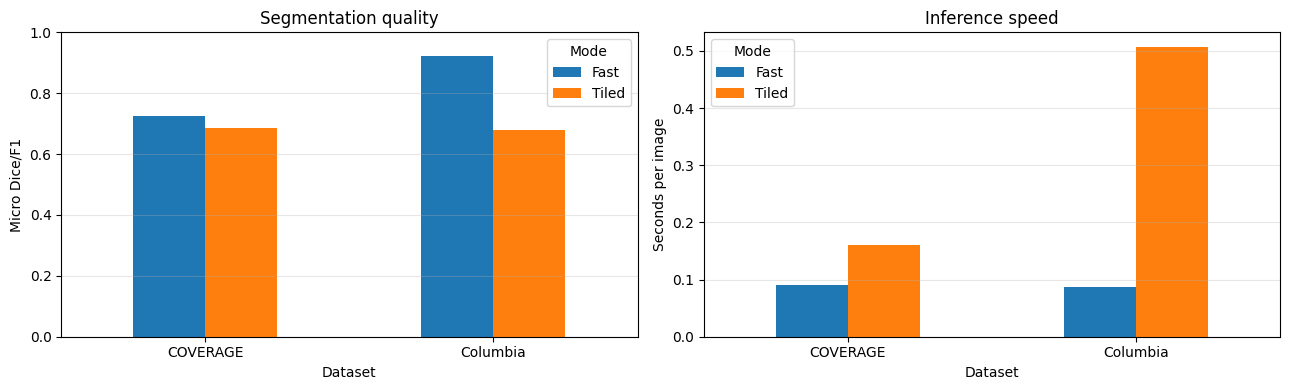

In [ ]:
# Visualize segmentation quality and average inference time for both datasets

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

benchmark_df.pivot(index="Dataset", columns="Mode", values="Micro F1").plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Segmentation quality")
axes[0].set_ylabel("Micro Dice/F1")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)

benchmark_df.pivot(index="Dataset", columns="Mode", values="Time (s/image)").plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Inference speed")
axes[1].set_ylabel("Seconds per image")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()